In [17]:
library( tidyverse )
options( repr.plot.height = 4 )
mytheme = function( font_size = 24 ) {
    (
        theme_minimal( font_size, base_family = "gill sans" )
        + theme(
            axis.title.y = element_text( angle = 0, hjust = 1, vjust = 0.5 )
        )
    )
}

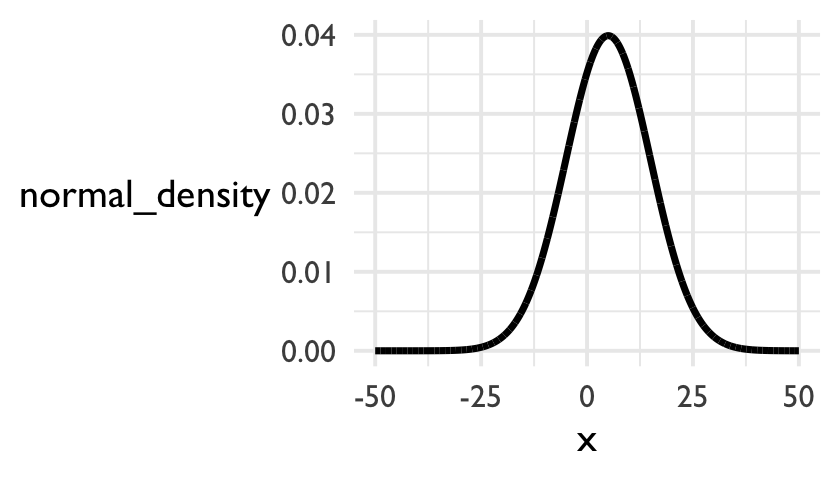

[1] -29.19928  49.19928

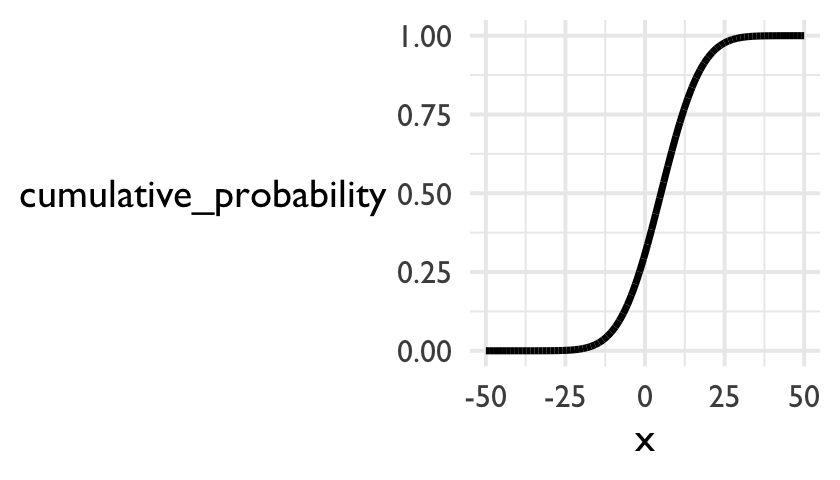

In [29]:
# Normal distribution example
# Let's plot the normal distribution

# We will use dnorm() to plot the density
# and pnorm() to look at the cumulative desnity
# and qnorm() to find the quantiles!

mean = 5
sd = 10
(
    ggplot(
        data = tibble::tibble(
            x = seq( from = -50, to = 50, by = 0.01 )
        ) %>% mutate(
            normal_density = dnorm( x, mean = mean, sd = sd )
        )
    )
    + geom_line( aes( x = x, y = normal_density ), linewidth = 2 )
    + mytheme()
)

(
    ggplot(
        data = tibble::tibble(
            x = seq( from = -50, to = 50, by = 0.01 )
        ) %>% mutate(
            cumulative_probability = pnorm( x, mean = 5, sd = 10 )
        )
    )
    + geom_line( aes( x = x, y = cumulative_probability ), linewidth = 2)
    + mytheme()
)

# How to find mass?  For example let's find out where 5% of the mass is:




In [32]:
print( "95% of the mass is between:" )
qnorm( c( 0.025, 0.975 ), mean = 0, sd = 1 )


[1] "95% of the mass is between:"


[1] -1.959964  1.959964

In [26]:
sprintf( "5%% of the mass is below: %.3f.", qnorm( 0.05, mean = 5, sd = 10 ))

[1] "5% of the mass is below: -11.449."

Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Warning message:
“Removed 982 rows containing missing values or values outside the scale range (`geom_col()`).”


[1] 0.002679432

[1] 0.9973206

[1] 0.9973206

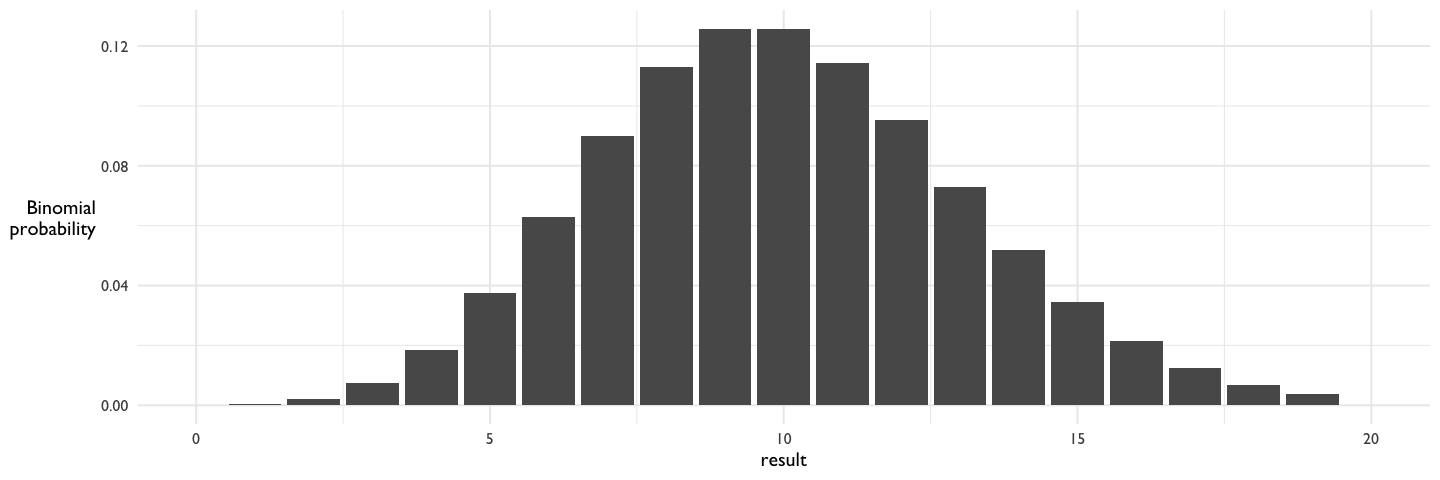

In [49]:
# Binomial distribution example

options( repr.plot.width = 12 )

n = 1000
# 1% frequency
p = 0.01

distribution = tibble::tibble(
    result = 0:n
) %>% mutate(
    binomial_probability = dbinom( result, size = n, prob = p )
)

(
    ggplot( distribution )
    + geom_col( aes( x = result, y = binomial_probability ))
    + scale_x_continuous( breaks = 0:n )
    + ylab( "Binomial\nprobability" )
    + xlim( 0, 20 )
    + mytheme( 12 )
)

# How much mass is under the tail? (I.e. what's the chance of seeing <= x?
x = 2
pbinom( x, size = 1000, prob = 0.01 )
1 - pbinom( x, size = 1000, prob = 0.01 )
pbinom( x, size = 1000, prob = 0.01, lower.tail = F )



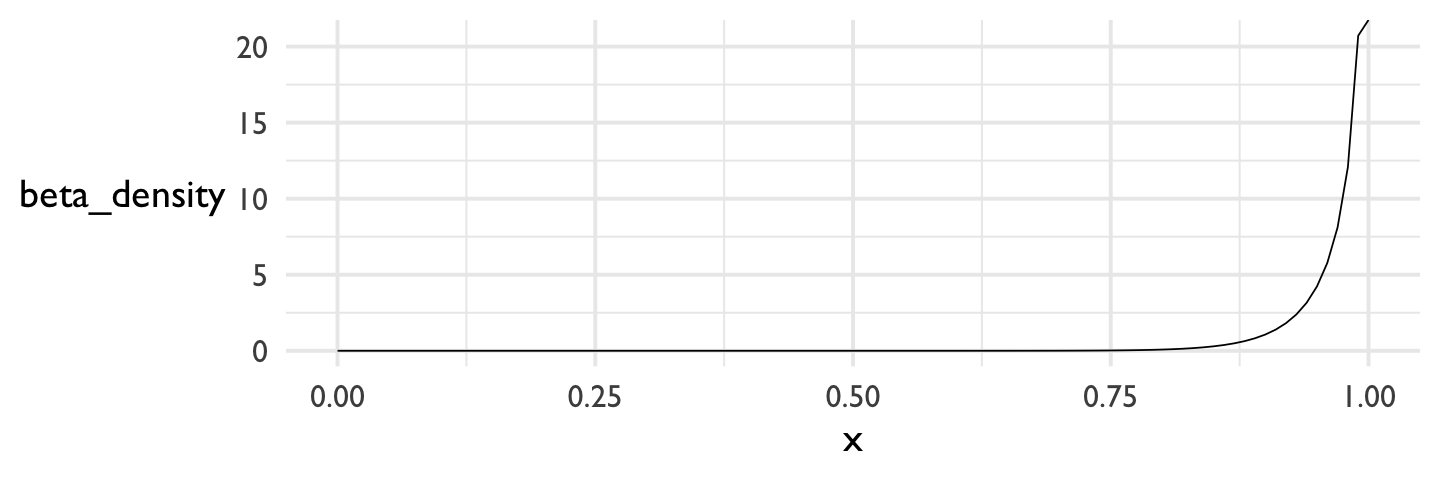

In [56]:
# beta example

alpha = 20

beta = 0.5
distribution = tibble::tibble(
    x = seq( from = 0, to = 1, by = 0.01 )
) %>% mutate( beta_density = dbeta( x, shape1 = alpha, shape2 = beta ))

(
    ggplot( data = distribution )
    + geom_line( aes( x = x, y = beta_density ))
    + mytheme()
)